# 03 -- Demand forecasting: LightGBM vs. baselines

Target: weekly units at brand x pack x store, 1-8 weeks ahead. Rolling-origin backtest with 9 folds
(origins every 8 weeks, test weeks 328-399). Code: `beverage_demand.forecasting.backtest`.
Planned price and promotion for the target week are treated as known in advance.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display
from beverage_demand.config import results, figure
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

In [2]:
m = pd.read_csv(results("forecast_metrics.csv"))
m[m["slice"].isin(["overall", "promo"])].pivot_table(index=["slice", "group"], columns="model", values="wape").round(3)

model                    lightgbm  moving_avg_4  regression  seasonal_naive
slice   group                                                              
overall all                 0.475         0.976       0.580           0.908
promo   non-promo weeks     0.400         2.737       0.449           1.975
        promo weeks         0.485         0.742       0.598           0.766

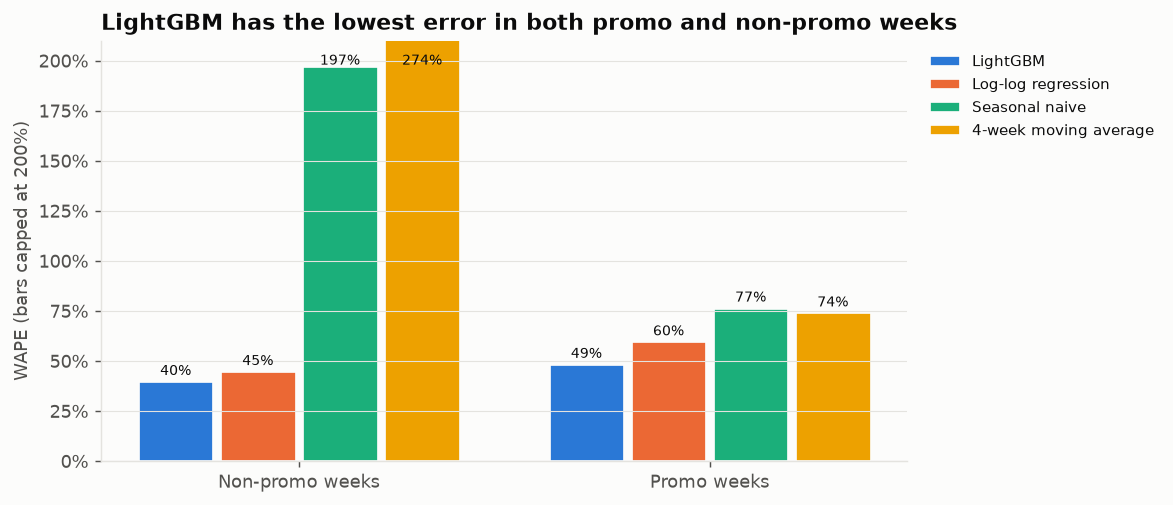

In [3]:
Image(filename=str(figure("forecast_wape_promo_split.png")))

**So what:** LightGBM has the lowest error overall and in promotion weeks. Naive baselines are
useless here because volume swings 4-16x between promoted and normal weeks; the log-log regression
is a solid baseline in normal weeks but loses accuracy in promo weeks, where LightGBM's
interactions between discount depth, promo type and recent sales help most.

In [4]:
m[m["slice"] == "series"].pivot_table(index="group", columns="model", values="wape").round(3)

model,lightgbm,moving_avg_4,regression,seasonal_naive
group,,,,
7Up | 24pk can,0.691,1.248,0.743,1.145
7Up | 2L,0.438,0.942,0.391,0.782
Coke | 24pk can,0.600,1.031,0.993,0.921
Coke | 2L,0.502,0.808,0.467,0.809
Diet Coke | 24pk can,0.581,1.026,0.846,0.930
Diet Coke | 2L,0.494,0.777,0.428,0.778
Diet Pepsi | 24pk can,0.443,0.996,0.744,1.010
Diet Pepsi | 2L,0.474,0.919,0.439,0.868
Pepsi | 24pk can,0.492,1.015,0.905,1.011


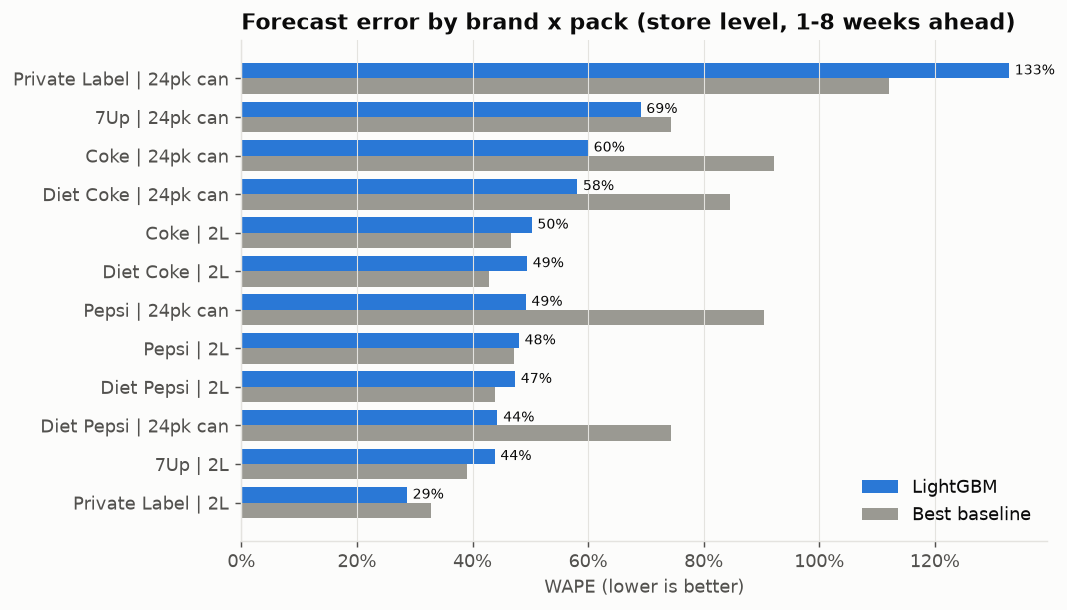

In [5]:
Image(filename=str(figure("forecast_wape_by_series.png")))

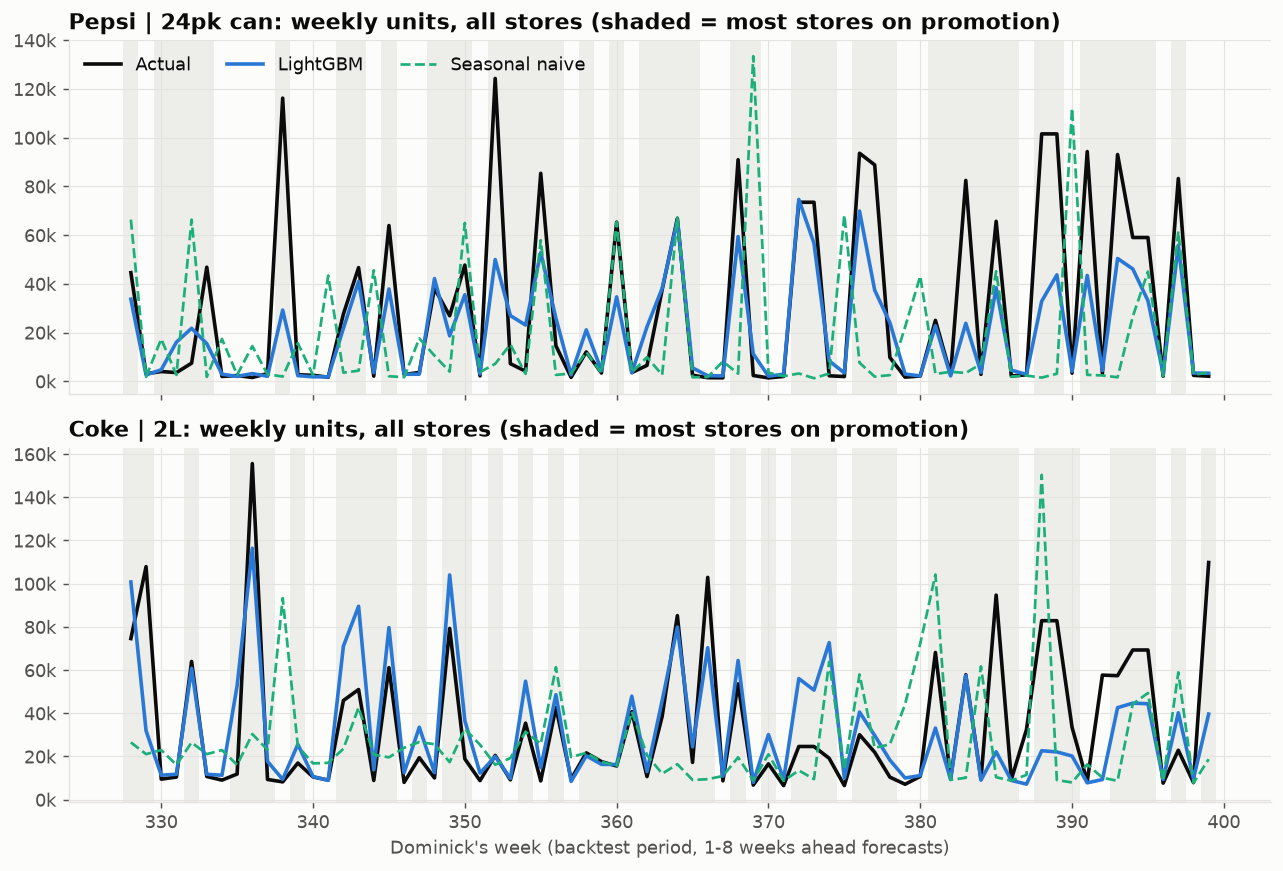

In [6]:
Image(filename=str(figure("forecast_actual_vs_forecast.png")))

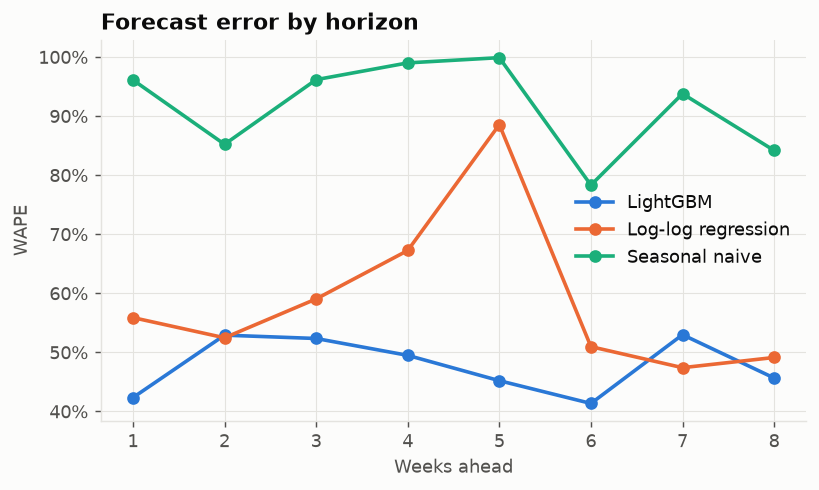

In [7]:
Image(filename=str(figure("forecast_wape_by_horizon.png")))

## What drives the forecast

In [8]:
pd.read_csv(results("forecast_shap_importance.csv")).head(12)

,Unnamed: 0,mean_abs_shap
0,discount depth,0.711
1,13-wk avg sales,0.408
2,own price (log),0.264
3,brand x pack,0.179
4,regular price (log),0.109
5,promo_u,0.091
6,price vs competitors,0.070
7,sin1,0.046
8,price-reduction flag,0.044
9,sales lag 1,0.043


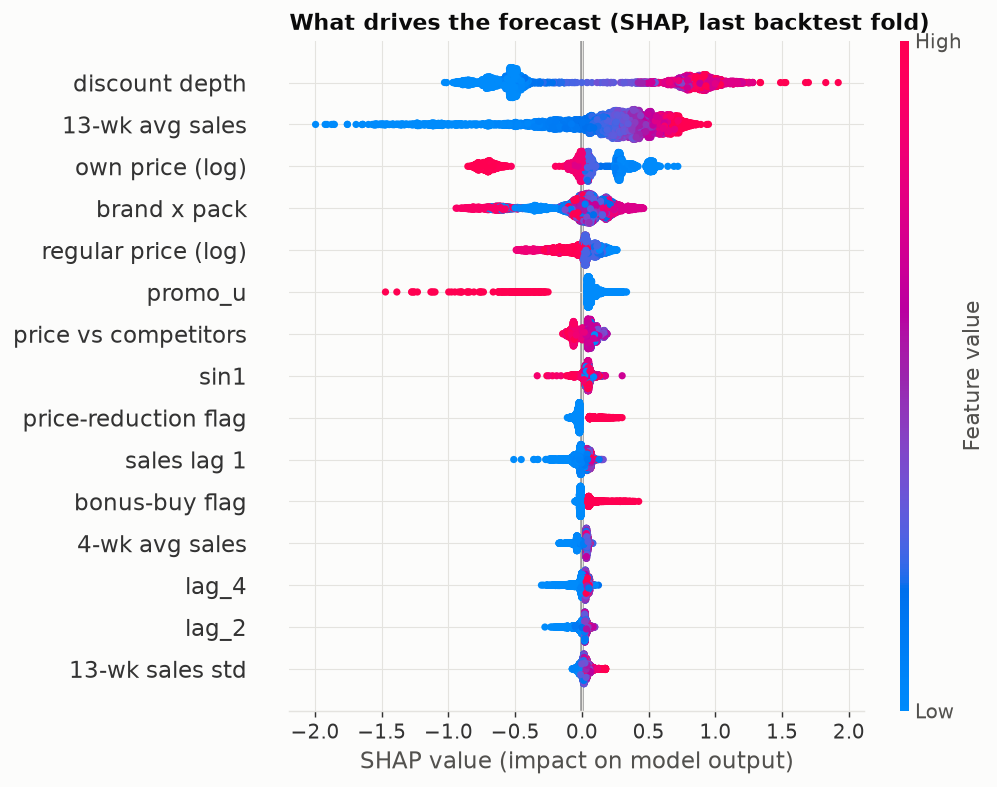

In [9]:
Image(filename=str(figure("forecast_shap_summary.png")))

**So what:** Discount depth is by far the biggest driver of next week's volume, followed by the
store's recent sales level and the price itself. In this category a forecast that does not know
the promotion plan cannot be accurate -- which is why sales and demand-planning teams need to share
the promo calendar.